# Entregable II — Análisis exploratorio y variables (20 %)

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante aprendizaje supervisado.
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia.

Este notebook reproduce el análisis individual de las 17 variables y el análisis
exploratorio que alimenta la sección del 20 % del Entregable II. Se apoya en
`src/proyecto_ml.py` y `src/analisis_variables.py`; las tablas se leen de
`resultados_corregidos/`.

> **Nota:** el análisis individual se calcula solo con el 60 % de entrenamiento. Para
> recalcularlo, ejecute `python src/analisis_variables.py` y vuelva a cargar las celdas.

In [1]:
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

import json
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Directorio de trabajo:", RAIZ)

Directorio de trabajo: C:\proyectos-git\proyecto-modelos-2-prediccion-intencion-compra


## 1. Carga y auditoría

Se verifican dimensiones, nulos, duplicados exactos y balance de clases antes de
particionar. Los duplicados exactos se eliminan para evitar fuga entre entrenamiento y
prueba.

In [2]:
from proyecto_ml import auditar, cargar_datos, tabla_auditoria

df = cargar_datos()
aud = auditar(df)
print(json.dumps({k: aud[k] for k in
      ["filas", "columnas", "nulos_totales", "duplicados_exactos",
       "clases", "proporcion_compra"]}, ensure_ascii=False, indent=2))
tabla_auditoria(df)

{
  "filas": 12330,
  "columnas": 18,
  "nulos_totales": 0,
  "duplicados_exactos": 125,
  "clases": {
    "False": 10422,
    "True": 1908
  },
  "proporcion_compra": 0.15474452554744525
}


,variable,tipo,n_unicos,min,max,media,nulos,categoria_mas_frecuente,frecuencia_max
0,Administrative,numerica,27,0.0,27.000000,2.315166,0,NaN,NaN
1,Administrative_Duration,numerica,3335,0.0,3398.750000,80.818611,0,NaN,NaN
2,Informational,numerica,17,0.0,24.000000,0.503569,0,NaN,NaN
3,Informational_Duration,numerica,1258,0.0,2549.375000,34.472398,0,NaN,NaN
4,ProductRelated,numerica,311,0.0,705.000000,31.731468,0,NaN,NaN
5,ProductRelated_Duration,numerica,9551,0.0,63973.522230,1194.746220,0,NaN,NaN
6,BounceRates,numerica,1872,0.0,0.200000,0.022191,0,NaN,NaN
7,ExitRates,numerica,4777,0.0,0.200000,0.043073,0,NaN,NaN
8,PageValues,numerica,2704,0.0,361.763742,5.889258,0,NaN,NaN
9,Month,categorica,10,NaN,NaN,NaN,0,May,3364.0


## 2. Distribución de clases y cobertura mensual

El conjunto tiene una prevalencia de compra cercana al 15,5 %. No hay sesiones de enero
ni de abril, de modo que el modelo no extrapola a esos meses.

In [3]:
conteo = df["Revenue"].value_counts().rename(index={False: "Sin compra", True: "Compra"})
print(conteo.to_string())
print("\nProporción de compra: {:.4f}".format(df["Revenue"].mean()))

Revenue
Sin compra    10422
Compra         1908

Proporción de compra: 0.1547


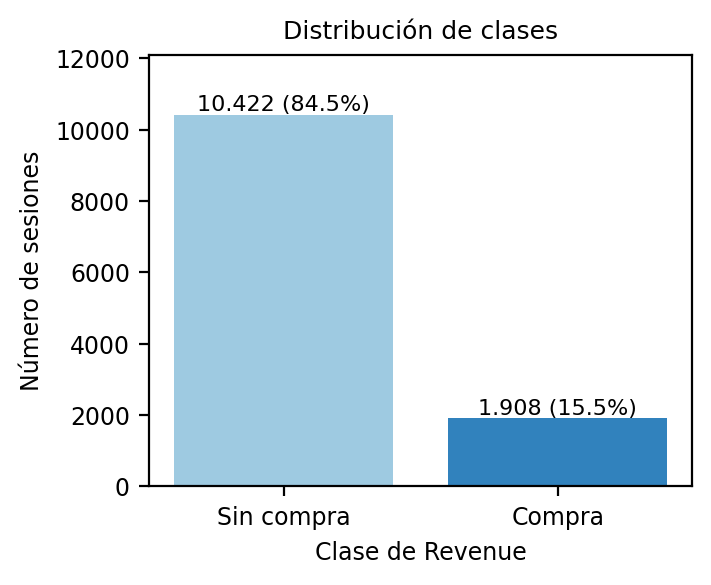

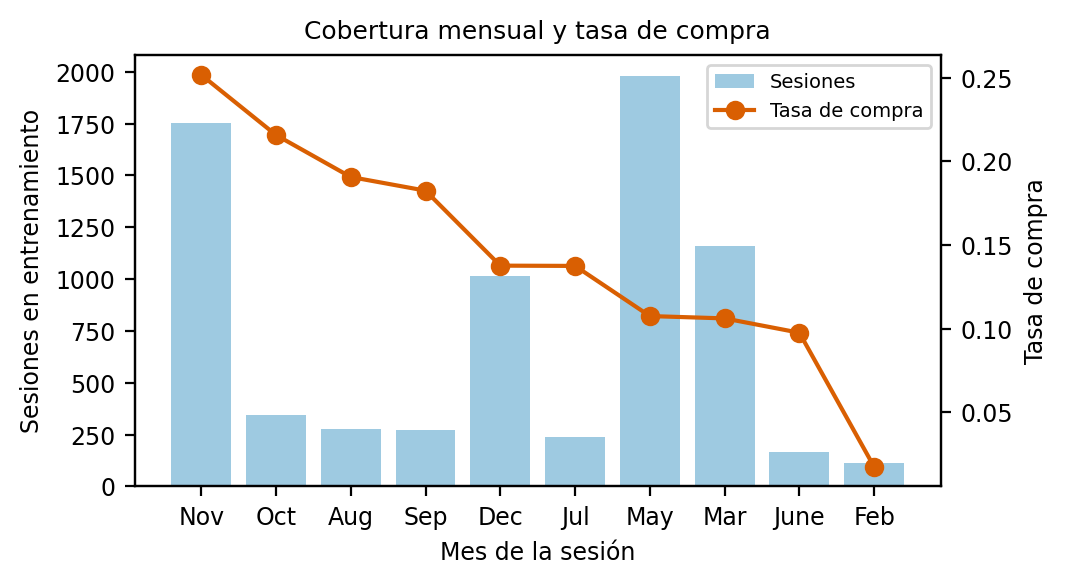

In [4]:
display(Image(filename="informe_entregable_II_latex/figuras/fig01_distribucion_clases.png"))
display(Image(filename="informe_entregable_II_latex/figuras/fig02_cobertura_mensual.png"))

## 3. Estadísticas descriptivas

Las variables numéricas tienen escalas muy distintas y asimetría positiva; por eso el
pipeline prueba `log(1+x)` antes de estandarizar.

In [5]:
from proyecto_ml import ESPECIALES, NUMERICAS

columnas = NUMERICAS + ESPECIALES
df[columnas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


## 4. Correlación entre variables numéricas

Dos pares superan $|r| = 0{,}8$: `ProductRelated` con `ProductRelated_Duration` y
`BounceRates` con `ExitRates`. Son candidatos a combinar en un modelo lineal.

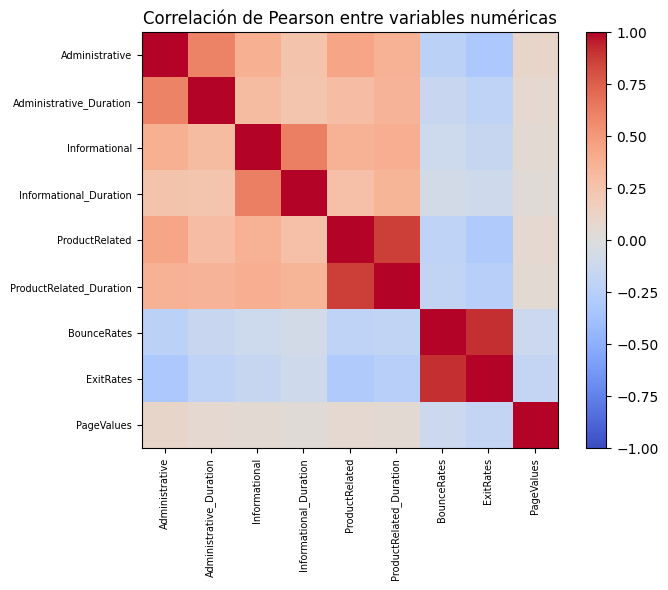

In [6]:
import matplotlib.pyplot as plt

corr = df[NUMERICAS].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticklabels(corr.columns, fontsize=7)
ax.set_title("Correlación de Pearson entre variables numéricas")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 5. Análisis individual de las 17 variables

El AUC univariado mide la capacidad de cada atributo para ordenar las sesiones por
compra. Para las categóricas se obtiene con una regresión logística sobre su codificación
one-hot, por lo que es una cota optimista; la V de Cramér y la información mutua
complementan la lectura.

In [7]:
analisis = pd.read_csv("resultados_corregidos/analisis_variables.csv")
analisis[["ranking", "variable", "tipo", "auc_univariado", "informacion_mutua", "recomendacion"]].round(4)

,ranking,variable,tipo,auc_univariado,informacion_mutua,recomendacion
0,1,PageValues,numérica,0.8664,0.1651,mantener
1,2,ExitRates,numérica,0.7101,0.0429,mantener
2,3,ProductRelated_Duration,numérica,0.6689,0.0317,mantener
3,4,ProductRelated,numérica,0.6582,0.0296,mantener
4,5,TrafficType,categórica,0.6341,0.0161,mantener
5,6,Administrative,numérica,0.6258,0.0157,mantener
6,7,Month,categórica,0.6254,0.0147,mantener
7,8,Administrative_Duration,numérica,0.6202,0.0136,mantener
8,9,BounceRates,numérica,0.6124,0.0268,mantener
9,10,Informational,numérica,0.5579,0.0067,revisar


In [8]:
redundancia = pd.read_csv("resultados_corregidos/redundancia_numericas.csv")
redundancia.round(4)

,variable_1,variable_2,correlacion
0,ProductRelated,ProductRelated_Duration,0.8426
1,BounceRates,ExitRates,0.8990


## 6. Lectura de resultados

- `PageValues` lidera con AUC 0,866 e información mutua 0,165; su retiro reduce el AP
  entre 0,34 y 0,39 en validación (ver `tab:pagevalues` del informe).
- `ExitRates` (0,710) y las variables de producto (0,669 y 0,658) le siguen.
- `Weekend` (0,513), `Region` (0,527) y `Browser` (0,527) aportan poco y son candidatas
  a eliminar o combinar.
- El análisis es descriptivo: el experimento principal mantiene todas las variables para
  no seleccionar con la etiqueta antes de particionar.